1. In this problem, you will perform K-means clustering manually, with
K = 2, on a small example with n = 6 observations and p = 2
features. The observations are as follows.

| Obs. | $X_1$ | $X_2$ |
|:----:|:-----:|:-----:|
| 1    | 1     | 4     |
| 2    | 1     | 3     |
| 3    | 0     | 4     |
| 4    | 5     | 1     |
| 5    | 6     | 2     |
| 6    | 4     | 0     |

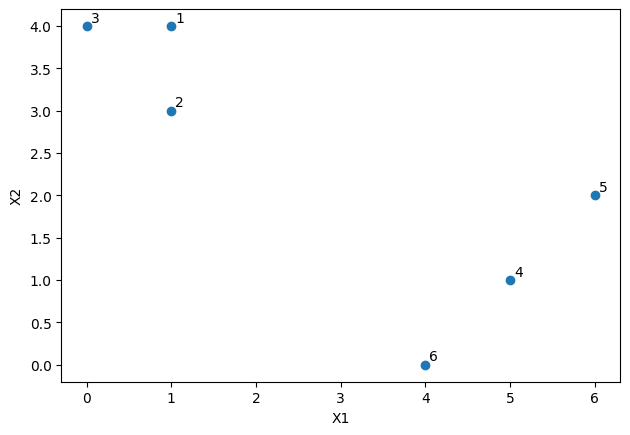

In [2]:
# (a) Plot the observations

import matplotlib.pyplot as plt
import numpy as np

X = np.array([
    [1, 4],
    [1, 3],
    [0, 4],
    [5, 1],
    [6, 2],
    [4, 0]
])

fig, ax = plt.subplots()

ax.scatter(X[:, 0], X[:, 1])
ax.set_xlabel('X1')
ax.set_ylabel('X2')
ax.set_aspect('equal')

for i, (x1, x2) in enumerate(X):
    ax.annotate(str(i + 1), (x1, x2), xytext=(3, 3), textcoords='offset points')

fig.tight_layout()


In [3]:
# (b) Randomly assign a cluster label to each observation. You can use
# the np.random.choice() function to do this. Report the cluster
# labels for each observation.

rng = np.random.default_rng(2)
labels = rng.choice([1, 2], len(X))
labels

array([2, 1, 1, 1, 1, 2])

In [4]:
# (c) Compute the centroid for each cluster.

def get_centroids(X: np.ndarray, labels: np.ndarray) -> tuple[np.ndarray, np.ndarray]:
    """Return centroids of cluster 1 and cluster 2."""

    cluster_1 = X[labels == 1]
    cluster_2 = X[labels == 2]
    
    return np.mean(cluster_1, axis=0), np.mean(cluster_2, axis=0)

get_centroids(X, labels)

(array([3. , 2.5]), array([2.5, 2. ]))

In [5]:
# (d) Assign each observation to the centroid to which it is closest, in
# terms of Euclidean distance. Report the cluster labels for each
# observation.

def assign(X: np.ndarray, centroid_1: np.ndarray, centroid_2: np.ndarray) -> np.ndarray:
    """Assign each point to the nearest centroid. Ties go to cluster 2."""

    distance_1 = np.linalg.norm(X - centroid_1, axis=1)
    distance_2 = np.linalg.norm(X - centroid_2, axis=1)
    labels = np.where(distance_1 < distance_2, 1, 2)
    return labels

centroid_1, centroid_2 = get_centroids(X, labels)
assign(X, centroid_1, centroid_2)

array([2, 2, 2, 1, 1, 2])

In [6]:
# (e) Repeat (c) and (d) until the answers obtained stop changing.

def k_means(X: np.ndarray, labels: np.ndarray) -> np.ndarray:
    """Repeat (c) and (d) until labels stop changing."""

    while True:
        centroid_1, centroid_2 = get_centroids(X, labels)
        new_labels = assign(X, centroid_1, centroid_2)
        if (np.array_equal(new_labels, labels)):
            return new_labels
        else: 
            labels = new_labels

final_labels = k_means(X, labels)
final_labels

array([2, 2, 2, 1, 1, 1])

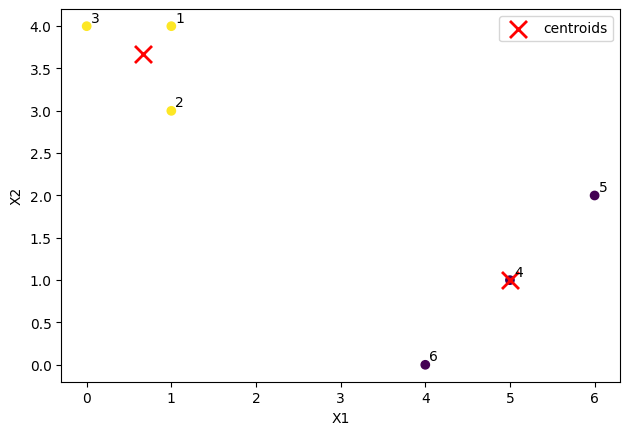

In [7]:
# (f) In your plot from (a), color the observations according to the
# cluster labels obtained.

centroid_1, centroid_2 = get_centroids(X, final_labels)
centroids = np.array([centroid_1, centroid_2])

fig, ax = plt.subplots()

ax.scatter(X[:, 0], X[:, 1], c=final_labels)
ax.scatter(centroids[:, 0], centroids[:, 1], marker='x', c='red', s=150, linewidths=2, label='centroids')
ax.set_xlabel('X1')
ax.set_ylabel('X2')
ax.set_aspect('equal')
ax.legend()

for i, (x1, x2) in enumerate(X):
    ax.annotate(str(i + 1), (x1, x2), xytext=(3, 3), textcoords='offset points')

fig.tight_layout()

<div style="border-top: 2px solid green;"></div>

2. In this chapter, we mentioned the use of correlation-based distance
and Euclidean distance as dissimilarity measures for hierarchical clustering. 
It turns out that these two measures are almost equivalent: if
each observation has been centered to have mean zero and standard
deviation one, and if we let rij denote the correlation between the ith
and jth observations, then the quantity 1− rij is proportional to the
squared Euclidean distance between the ith and jth observations.
On the USArrests data, show that this proportionality holds.

In [8]:
import os
import certifi

os.environ['SSL_CERT_FILE'] = certifi.where()

In [9]:
from statsmodels.datasets import get_rdataset

USArrests = get_rdataset("USArrests").data
USArrests.shape, USArrests

((50, 4),
                 Murder  Assault  UrbanPop  Rape
 rownames                                       
 Alabama           13.2      236        58  21.2
 Alaska            10.0      263        48  44.5
 Arizona            8.1      294        80  31.0
 Arkansas           8.8      190        50  19.5
 California         9.0      276        91  40.6
 Colorado           7.9      204        78  38.7
 Connecticut        3.3      110        77  11.1
 Delaware           5.9      238        72  15.8
 Florida           15.4      335        80  31.9
 Georgia           17.4      211        60  25.8
 Hawaii             5.3       46        83  20.2
 Idaho              2.6      120        54  14.2
 Illinois          10.4      249        83  24.0
 Indiana            7.2      113        65  21.0
 Iowa               2.2       56        57  11.3
 Kansas             6.0      115        66  18.0
 Kentucky           9.7      109        52  16.3
 Louisiana         15.4      249        66  22.2
 Maine    

In [10]:
X = np.array(USArrests)

mean = np.mean(X, axis=1, keepdims=True)
std = np.std(X, axis=1, keepdims=True)

X_scaled = (X - mean) / std

print(np.allclose(X_scaled.mean(axis=1), 0))
print(np.mean(X_scaled, axis=1, keepdims=True))
print(np.std(X_scaled, axis=1, keepdims=True))


True
[[ 5.55111512e-17]
 [-2.77555756e-17]
 [-1.11022302e-16]
 [-2.77555756e-17]
 [-8.32667268e-17]
 [ 1.38777878e-16]
 [-2.77555756e-17]
 [-2.77555756e-17]
 [ 8.32667268e-17]
 [-2.77555756e-17]
 [-5.55111512e-17]
 [ 1.11022302e-16]
 [ 5.55111512e-17]
 [ 1.11022302e-16]
 [ 0.00000000e+00]
 [ 0.00000000e+00]
 [ 5.55111512e-17]
 [ 1.11022302e-16]
 [-5.55111512e-17]
 [-5.55111512e-17]
 [-8.32667268e-17]
 [-1.38777878e-16]
 [ 8.32667268e-17]
 [-1.11022302e-16]
 [ 5.55111512e-17]
 [-5.55111512e-17]
 [-8.32667268e-17]
 [-2.77555756e-17]
 [ 5.55111512e-17]
 [ 0.00000000e+00]
 [ 0.00000000e+00]
 [-1.66533454e-16]
 [-5.55111512e-17]
 [ 1.38777878e-16]
 [-1.66533454e-16]
 [-2.77555756e-17]
 [ 5.55111512e-17]
 [-1.38777878e-16]
 [ 5.55111512e-17]
 [ 8.32667268e-17]
 [-2.22044605e-16]
 [ 1.11022302e-16]
 [ 5.55111512e-17]
 [ 5.55111512e-17]
 [-8.32667268e-17]
 [ 8.32667268e-17]
 [ 1.11022302e-16]
 [-2.77555756e-17]
 [-2.77555756e-17]
 [ 0.00000000e+00]]
[[1.]
 [1.]
 [1.]
 [1.]
 [1.]
 [1.]
 [1.]
 [

In [11]:
corr_coef = np.corrcoef(X_scaled)
corr_coef

array([[1.        , 0.99092502, 0.99856984, ..., 0.96759749, 0.58753266,
        0.98911539],
       [0.99092502, 1.        , 0.98969621, ..., 0.93489972, 0.51058785,
        0.96749454],
       [0.99856984, 0.98969621, 1.        , ..., 0.97553899, 0.61849688,
        0.99361584],
       ...,
       [0.96759749, 0.93489972, 0.97553899, ..., 1.        , 0.7724072 ,
        0.99407361],
       [0.58753266, 0.51058785, 0.61849688, ..., 0.7724072 , 1.        ,
        0.7001675 ],
       [0.98911539, 0.96749454, 0.99361584, ..., 0.99407361, 0.7001675 ,
        1.        ]])

In [45]:
from sklearn.metrics import pairwise_distances, pairwise

distances = pairwise_distances(X_scaled) ** 2
distances

array([[0.        , 0.07259981, 0.01144126, ..., 0.25922012, 3.29973872,
        0.08707686],
       [0.07259981, 0.        , 0.08243033, ..., 0.52080222, 3.91529719,
        0.2600437 ],
       [0.01144126, 0.08243033, 0.        , ..., 0.19568808, 3.05202493,
        0.0510733 ],
       ...,
       [0.25922012, 0.52080222, 0.19568808, ..., 0.        , 1.82074238,
        0.04741111],
       [3.29973872, 3.91529719, 3.05202493, ..., 1.82074238, 0.        ,
        2.39866002],
       [0.08707686, 0.2600437 , 0.0510733 , ..., 0.04741111, 2.39866002,
        0.        ]])

In [13]:
idxs = np.triu_indices(len(X_scaled), k=1)

proportional = distances[idxs] / (1 - corr_coef[idxs])

proportional

array([8., 8., 8., ..., 8., 8., 8.])

In [14]:
np.allclose(proportional, 8)

True

<div style="border-top: 2px solid green;"></div>

3. 8. In Section 12.2.3, a formula for calculating PVE was given in Equa-
tion 12.10. We also saw that the PVE can be obtained using the
explained_variance_ratio_ attribute of a fitted PCA() estimator.
On the USArrests data, calculate PVE in two ways:

In [15]:
# (a) Using the explained_variance_ratio_ output of the fitted PCA()
# estimator, as was done in Section 12.2.3.

from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

USArrests_scaled = scaler.fit_transform(USArrests)

pca_us = PCA().fit(USArrests_scaled)

pca_us.explained_variance_ratio_

array([0.62006039, 0.24744129, 0.0891408 , 0.04335752])

In [16]:
# (b) By applying Equation 12.10 directly. The loadings are stored
# as the components_ attribute of the fitted PCA() estimator. Use
# those loadings in Equation 12.10 to obtain the PVE.

loadings = pca_us.components_
scores = pca_us.transform(X_scaled) 
# scores = pca_us.transform(USArrests_scaled)
numerator = np.sum(scores ** 2, axis=0)
denominator = np.sum(USArrests_scaled ** 2)

pve = numerator / denominator
pve

array([0.00424269, 0.06296057, 0.134914  , 0.79788274])

<div style="border-top: 2px solid green;"></div>

4. Consider the USArrests data. We will now perform hierarchical clustering on the states.

In [17]:
# (a) Using hierarchical clustering with complete linkage and
# Euclidean distance, cluster the states.

from sklearn.cluster import AgglomerativeClustering as HClust

hc_comp = HClust(linkage="complete", metric='euclidean', n_clusters=None, distance_threshold=0).fit(USArrests)

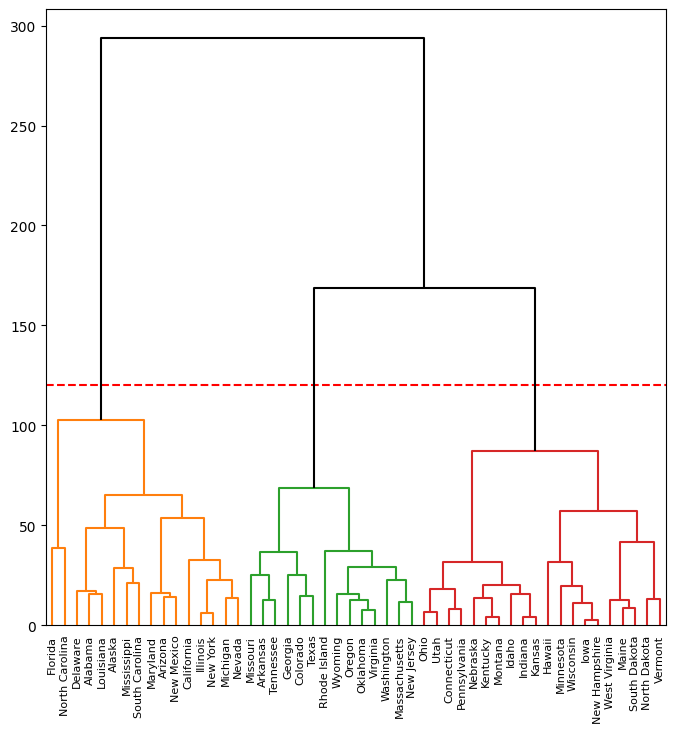

In [18]:
# (b) Cut the dendrogram at a height that results in three distinct
# clusters. Which states belong to which clusters?

from scipy.cluster.hierarchy import \
     (dendrogram,
      cut_tree)
from ISLP.cluster import compute_linkage

# cargs = {'color_threshold':-np.inf,
#          'above_threshold_color':'black'}

linkage_comp = compute_linkage(hc_comp)
fig, ax = plt.subplots(1, 1, figsize=(8, 8))
ax.axhline(y=120, color='red', linestyle='--')
dendrogram(linkage_comp,
           ax=ax,
           labels=USArrests.index,
           color_threshold=120,
           above_threshold_color='black');



In [19]:
import pandas as pd

comp_cut = cut_tree(linkage_comp, height=120).reshape(-1)
clusters = pd.Series(comp_cut, index=USArrests.index, name='cluster')

for label, states in clusters.groupby(clusters):
    print(label, list(states.index))

0 ['Alabama', 'Alaska', 'Arizona', 'California', 'Delaware', 'Florida', 'Illinois', 'Louisiana', 'Maryland', 'Michigan', 'Mississippi', 'Nevada', 'New Mexico', 'New York', 'North Carolina', 'South Carolina']
1 ['Arkansas', 'Colorado', 'Georgia', 'Massachusetts', 'Missouri', 'New Jersey', 'Oklahoma', 'Oregon', 'Rhode Island', 'Tennessee', 'Texas', 'Virginia', 'Washington', 'Wyoming']
2 ['Connecticut', 'Hawaii', 'Idaho', 'Indiana', 'Iowa', 'Kansas', 'Kentucky', 'Maine', 'Minnesota', 'Montana', 'Nebraska', 'New Hampshire', 'North Dakota', 'Ohio', 'Pennsylvania', 'South Dakota', 'Utah', 'Vermont', 'West Virginia', 'Wisconsin']


In [20]:
# (c) Hierarchically cluster the states using complete linkage and 
# Euclidean distance, after scaling the variables to have standard deviation one.

from sklearn.pipeline import Pipeline

pipeline = Pipeline([
    ("scaler", StandardScaler(with_mean=False)),
    ("hclust", HClust(linkage="complete", metric='euclidean', n_clusters=None, distance_threshold=0)),
])

pipeline.fit(USArrests)



,steps,"[('scaler', ...), ('hclust', ...)]"
,transform_input,None
,memory,None
,verbose,False
,copy,True
,with_mean,False
,with_std,True
,n_clusters,None
,metric,'euclidean'
,memory,None
,connectivity,None


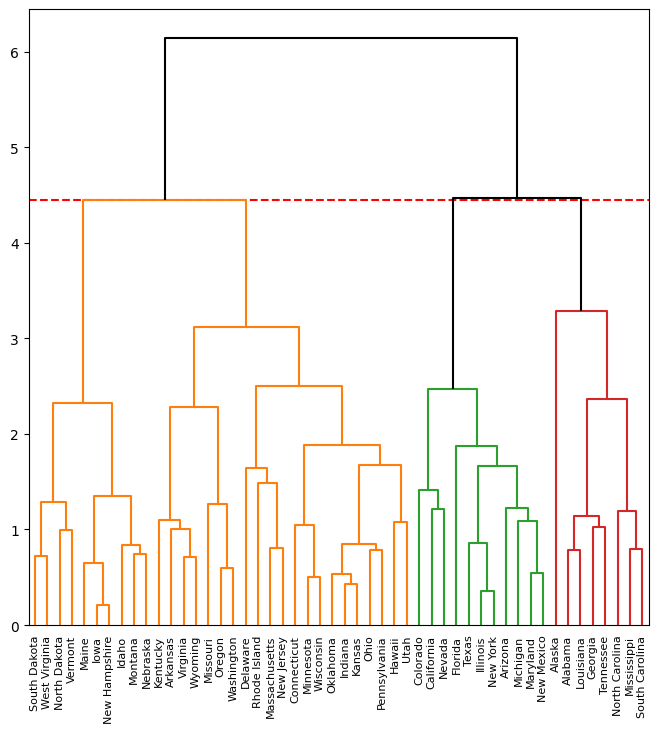

In [21]:
linkage_scaled = compute_linkage(pipeline.named_steps["hclust"])
fig, ax = plt.subplots(1, 1, figsize=(8, 8))
ax.axhline(y=4.45, color='red', linestyle='--')
dendrogram(linkage_scaled,
           ax=ax,
           labels=USArrests.index,
           color_threshold=4.45,
           above_threshold_color='black');

In [22]:
comp_cut_scaled = cut_tree(linkage_scaled, n_clusters=3).reshape(-1)
clusters_scaled = pd.Series(comp_cut_scaled, index=USArrests.index, name='cluster')

for label, states in clusters_scaled.groupby(clusters_scaled):
    print(label, list(states.index))

0 ['Alabama', 'Alaska', 'Georgia', 'Louisiana', 'Mississippi', 'North Carolina', 'South Carolina', 'Tennessee']
1 ['Arizona', 'California', 'Colorado', 'Florida', 'Illinois', 'Maryland', 'Michigan', 'Nevada', 'New Mexico', 'New York', 'Texas']
2 ['Arkansas', 'Connecticut', 'Delaware', 'Hawaii', 'Idaho', 'Indiana', 'Iowa', 'Kansas', 'Kentucky', 'Maine', 'Massachusetts', 'Minnesota', 'Missouri', 'Montana', 'Nebraska', 'New Hampshire', 'New Jersey', 'North Dakota', 'Ohio', 'Oklahoma', 'Oregon', 'Pennsylvania', 'Rhode Island', 'South Dakota', 'Utah', 'Vermont', 'Virginia', 'Washington', 'West Virginia', 'Wisconsin', 'Wyoming']


In [23]:
# (d) What effect does scaling the variables have on the hierarchical
# clustering obtained? In your opinion, should the variables be
# scaled before the inter-observation dissimilarities are computed?
# Provide a justification for your answer.

pd.crosstab(comp_cut, comp_cut_scaled, rownames=['raw'], colnames=['scaled'])

scaled,0,1,2
raw,,,
0,6,9,1
1,2,2,10
2,0,0,20


In [24]:
USArrests.groupby(comp_cut).mean()

,Murder,Assault,UrbanPop,Rape
0,11.812500,272.562500,68.312500,28.375000
1,8.214286,173.285714,70.642857,22.842857
2,4.270000,87.550000,59.750000,14.390000


In [25]:
USArrests.groupby(comp_cut_scaled).mean()

,Murder,Assault,UrbanPop,Rape
0,14.087500,252.750000,53.500000,24.537500
1,11.054545,264.090909,79.090909,32.618182
2,5.003226,116.483871,63.838710,16.338710


<div style="border-top: 2px solid green;"></div>

5. In this problem, you will generate simulated data, and then perform
PCA and K-means clustering on the data.

In [26]:
# (a) Generate a simulated data set with 20 observations in each of
# three classes (i.e. 60 observations total), and 50 variables.

rng = np.random.default_rng(2)

X = rng.uniform(size=(60, 50))
X[20:40, 20:40] += 1
X[40:, 40:] -= 1

true_labels = np.repeat([0, 1, 2], 20)


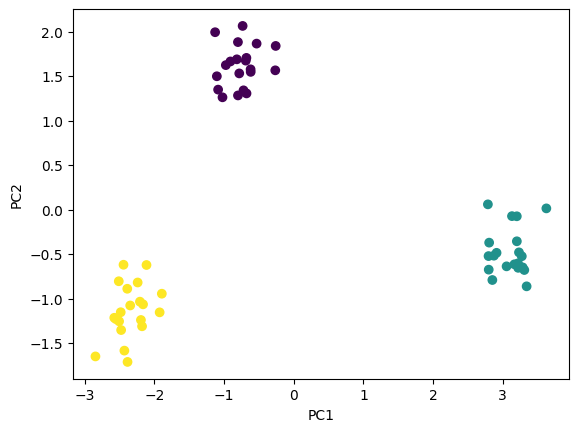

In [27]:
# (b) Perform PCA on the 60 observations and plot the first two 
# principal component score vectors. Use a different color to indicate
# the observations in each of the three classes. If the three classes
# appear separated in this plot, then continue on to part (c). 
# If not, then return to part (a) and modify the simulation so that
# there is greater separation between the three classes. Do not
# continue to part (c) until the three classes show at least some
# separation in the first two principal component score vectors.

pca = PCA(n_components=2).fit(X)

scores = pca.transform(X)

fig, ax = plt.subplots()

ax.scatter(scores[:, 0], scores[:, 1], c=true_labels);
ax.set_xlabel("PC1")
ax.set_ylabel("PC2");


In [28]:
# (c) Perform K-means clustering of the observations with K = 3.
# How well do the clusters that you obtained in K-means 
# clustering compare to the true class labels?

from sklearn.cluster import KMeans

k_means = KMeans(n_clusters=3, n_init=20, random_state=2).fit(X)

pd.crosstab(true_labels, k_means.labels_, rownames=["true_labels"], colnames=["k_means labels"])

k_means labels,0,1,2
true_labels,,,
0,0,0,20
1,20,0,0
2,0,20,0


In [29]:
# (d) Perform K-means clustering with K = 2. Describe your results.

k_means = KMeans(n_clusters=2, n_init=20, random_state=2).fit(X)

pd.crosstab(true_labels, k_means.labels_, rownames=["true_labels"], colnames=["k_means labels"])

k_means labels,0,1
true_labels,,
0,0,20
1,20,0
2,0,20


In [30]:
# (e) Now perform K-means clustering with K = 4, and describe your
# results.

k_means = KMeans(n_clusters=4, n_init=20, random_state=2).fit(X)

pd.crosstab(true_labels, k_means.labels_, rownames=["true_labels"], colnames=["k_means labels"])

k_means labels,0,1,2,3
true_labels,,,,
0,0,0,6,14
1,0,20,0,0
2,20,0,0,0


In [31]:
# (f) Now perform K-means clustering with K = 3 on the first two
# principal component score vectors, rather than on the raw data.
# That is, perform K-means clustering on the 60 × 2 matrix of
# which the first column is the first principal component score
# vector, and the second column is the second principal component
# score vector. Comment on the results.

k_means = KMeans(n_clusters=3, n_init=20, random_state=2).fit(scores)

pd.crosstab(true_labels, k_means.labels_, rownames=["true_labels"], colnames=["k_means labels"])

k_means labels,0,1,2
true_labels,,,
0,0,20,0
1,20,0,0
2,0,0,20


In [32]:
# (g) Using the StandardScaler() estimator, perform K-means 
# clustering with K = 3 on the data after scaling each variable to have
# standard deviation one. How do these results compare to those
# obtained in (b)? Explain.

pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("k_means", KMeans(n_clusters=3, n_init=20, random_state=2))
])

pipeline.fit(X)

pd.crosstab(true_labels, pipeline.named_steps["k_means"].labels_, rownames=["true_labels"], colnames=["k_means labels"])

k_means labels,0,1,2
true_labels,,,
0,0,0,20
1,20,0,0
2,0,20,0


<div style="border-top: 2px solid green;"></div>

6. On the book website, www.statlearning.com, there is a gene expression data set (Ch12Ex13.csv) that consists of 40 tissue samples with
measurements on 1,000 genes. The first 20 samples are from healthy
patients, while the second 20 are from a diseased group.

In [39]:
# (a) Load in the data using pd.read_csv(). 
# You will need to select header = None.

gene_expression = pd.read_csv("Ch12Ex13.csv", header=None).T
gene_expression.shape


(40, 1000)

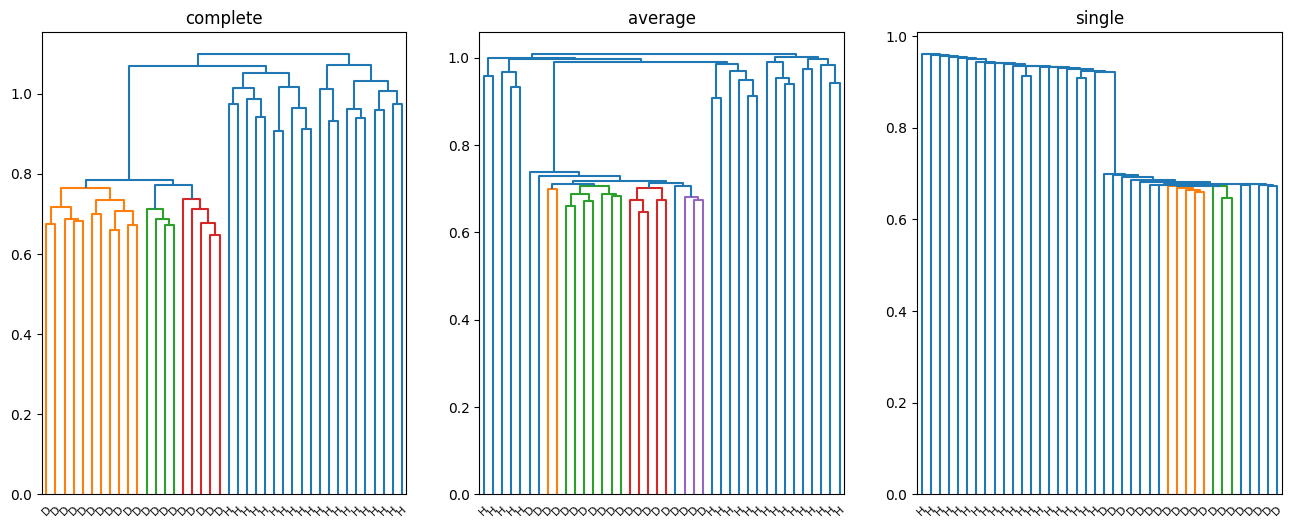

In [88]:
# (b) Apply hierarchical clustering to the samples using 
# correlationbased distance, and plot the dendrogram. Do the genes separate
# the samples into the two groups? Do your results depend on the
# type of linkage used?

true_labels = np.repeat([0, 1], 20)

D = pairwise_distances(gene_expression, metric='correlation')

fig, ax = plt.subplots(1, 3, figsize=(16, 6))

for idx, i in enumerate(["complete", "average", "single"]):
    hc_comp = HClust(metric="precomputed", linkage=i, distance_threshold=0,
                    n_clusters=None).fit(D)

    linkage_comp = compute_linkage(hc_comp)

    dendrogram(linkage_comp, ax=ax[idx], labels=np.repeat(['H', 'D'], 20));
    ax[idx].set_title(i)